In [1]:
#1 Post-imputation verification EDA — run on X_train only
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
X_train = pd.read_csv("X_train_clean.csv")  

In [3]:
# Basic sanity checks
print("Missing values remaining:", X_train.isnull().sum().sum())
print("\nSummary statistics (post-imputation):")
print(X_train.describe())

Missing values remaining: 0

Summary statistics (post-imputation):
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   614.000000  614.000000     614.000000     614.000000  614.000000   
mean      3.819218  121.671010      72.140065      29.054552  148.346966   
std       3.314148   30.003794      12.275119       9.558854   90.155329   
min       0.000000   56.000000      24.000000       7.000000   15.000000   
25%       1.000000   99.000000      64.000000      22.758929   87.000000   
50%       3.000000  117.000000      72.000000      29.000000  129.433837   
75%       6.000000  140.000000      80.000000      35.000000  187.109985   
max      17.000000  199.000000     122.000000      99.000000  744.000000   

              BMI  DiabetesPedigreeFunction         Age  
count  614.000000                614.000000  614.000000  
mean    32.448208                  0.477428   33.366450  
std      6.824122                  0.330300   11.833438  
min     18.20000

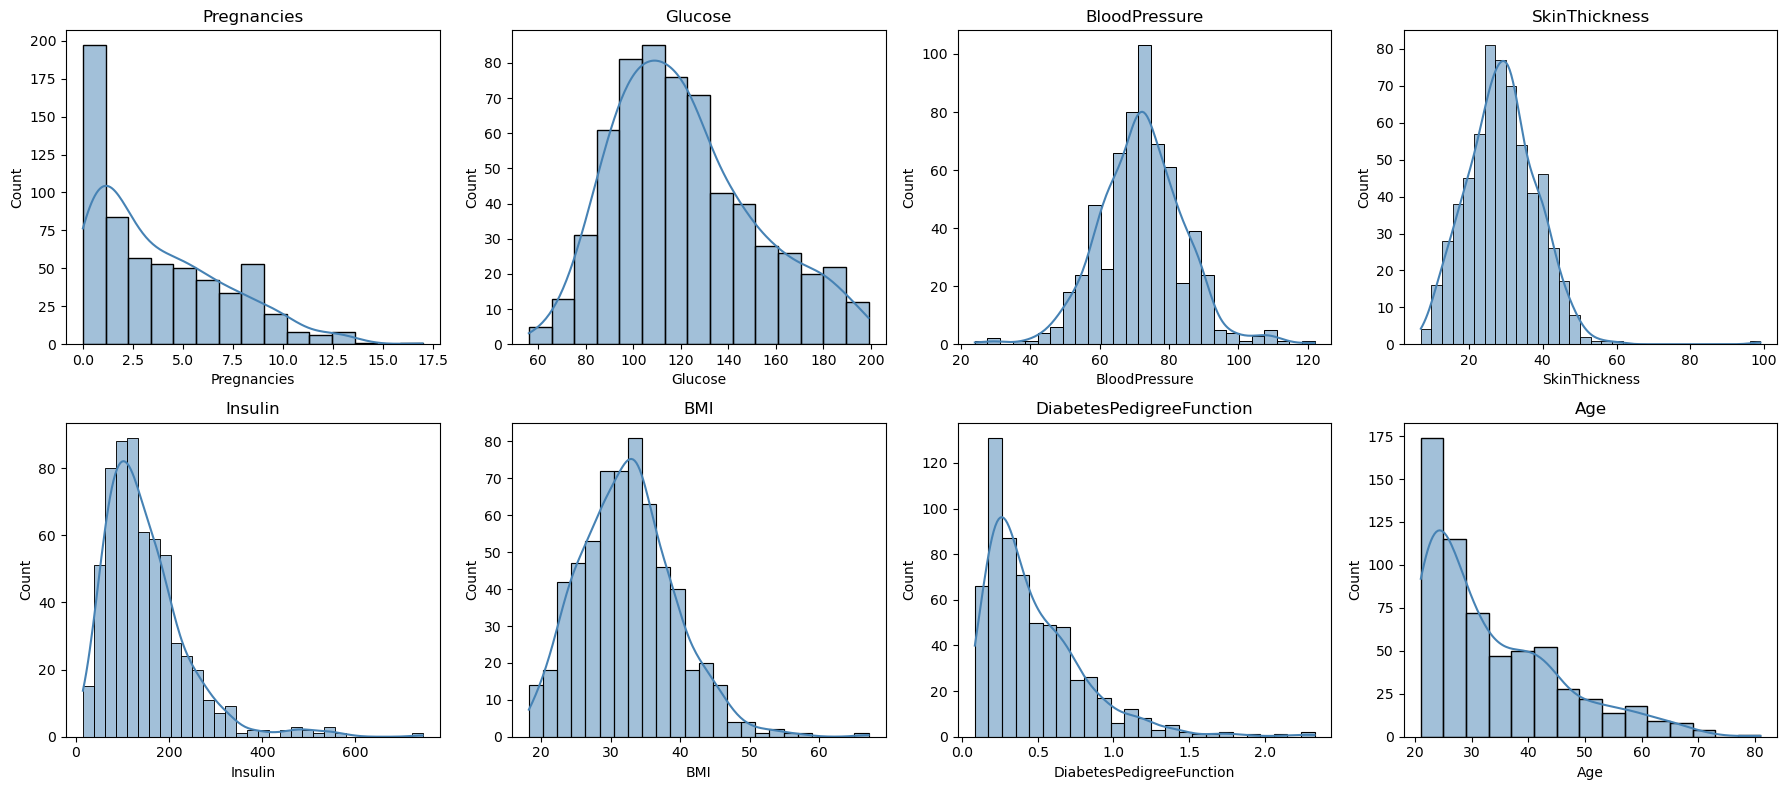

In [4]:
#2 Distribution plots to check for implausible imputation artifacts
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), X_train.columns):
    sns.histplot(X_train[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

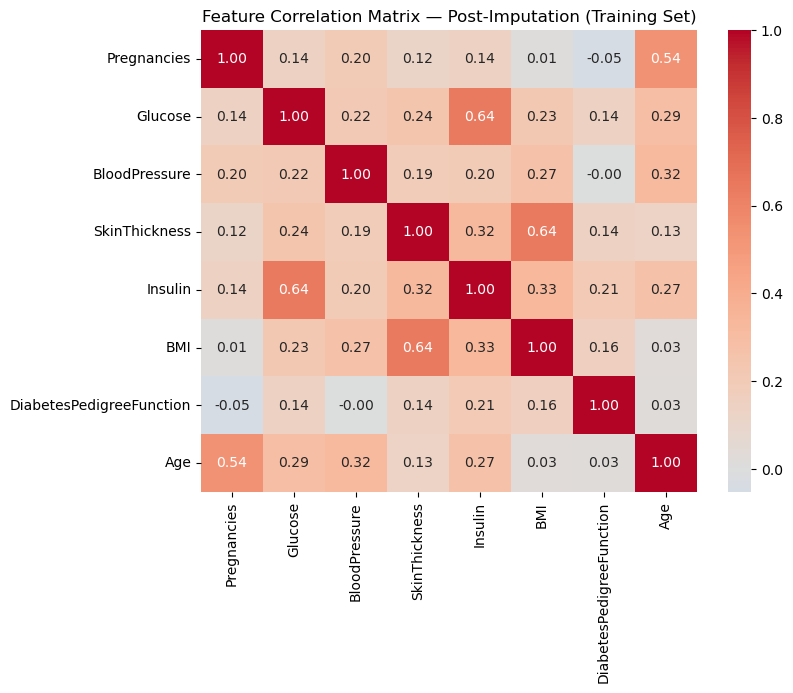

In [5]:
#3 Correlation check — confirm imputation didn't distort known relationships
plt.figure(figsize=(8, 6))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlation Matrix — Post-Imputation (Training Set)")
plt.show()

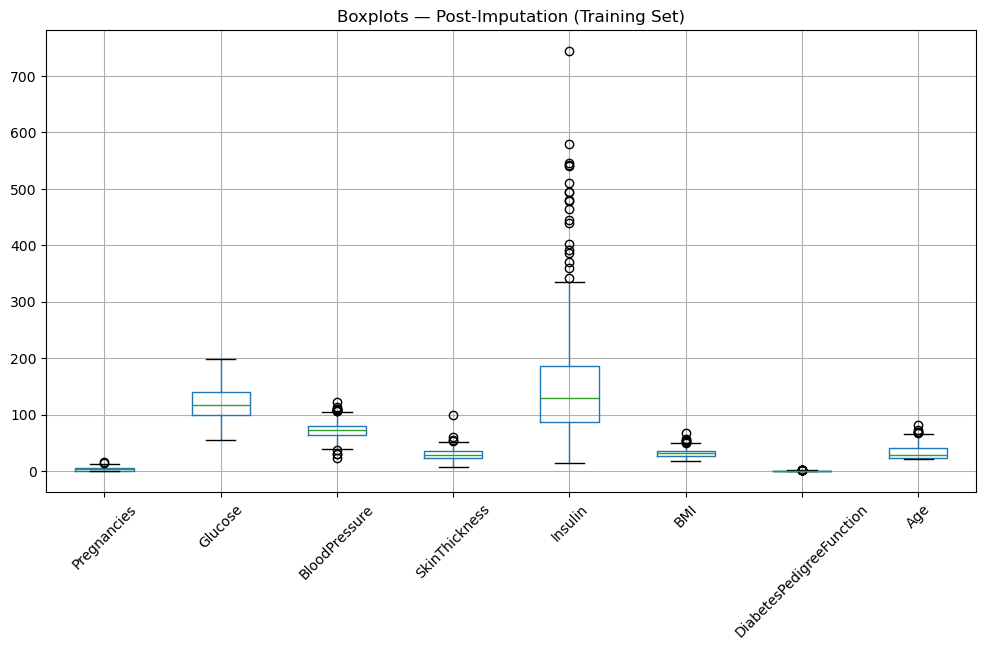

In [6]:
#4 Boxplots — check for implausible outliers introduced by imputation
plt.figure(figsize=(12, 6))
X_train.boxplot()
plt.xticks(rotation=45)
plt.title("Boxplots — Post-Imputation (Training Set)")
plt.show()